# Notebook 11 — Customer Retention Trajectory Clustering and Functional Data Analysis

This study tests whether exposure-aware historical purchasing paths add descriptive or predictive information beyond static RFM and the existing saved Purchase Clock. A distinct-looking curve is not, by itself, evidence of a stable cluster, churn risk, or incremental predictive value.

**Research project:** Customer Segmentation and Retention Analysis Using Machine Learning and Statistical Modelling  
**Historical source period:** 2009-12-01 through 2010-12-09  
**Official out-of-time cutoff:** 2010-09-10  
**Reproducibility:** Python 3.11 with the repository's hash-locked `requirements-ci.txt`.

## 1. Introduction and research motivation
## 2. Research questions and hypotheses
The study separates longitudinal structure, cluster stability, functional representation, retrospective future-purchase association, and incremental prediction. Hypotheses are not assumed to be supported.

## 3. Historical data and longitudinal limitations
The source is invoice-level, left-truncated retail history. A customer's first observed invoice is not assumed to be their acquisition date; periods before that event remain unobserved rather than being filled with zero purchases.

In [1]:
from pathlib import Path
import json
import os
import platform
import resource
import sys
import time
import tracemalloc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
tracemalloc.start()
analysis_started = time.perf_counter()
profile_timings_ms = {
    'trajectory_matrix_construction_ms': 0.0,
    'feature_engineering_ms': 0.0,
    'clustering_fit_ms': 0.0,
    'cluster_stability_evaluation_ms': 0.0,
    'cluster_assignment_ms': 0.0,
    'functional_fit_ms': 0.0,
    'functional_curve_evaluation_ms': 0.0,
    'functional_transform_ms': 0.0,
    'functional_stability_evaluation_ms': 0.0,
}

from src.behavior_monitor import compute_behavior_features, prepare_purchase_events
from src.customer_trajectories import (
    TrajectoryConfig,
    build_customer_trajectory_matrix,
    calculate_trajectory_features,
)
from src.functional_trajectory_analysis import (
    FunctionalTrajectoryConfig,
    evaluate_functional_component_stability,
    evaluate_functional_representation,
    fit_functional_representation,
    transform_functional_representation,
)
from src.trajectory_clustering import (
    DEFAULT_CLUSTER_FEATURES,
    TrajectoryClusteringConfig,
    assign_trajectory_clusters,
    build_shape_trajectory_features,
    compare_static_dynamic_segments,
    evaluate_cluster_stability,
    fit_trajectory_clusters,
    prepare_trajectory_features,
    transform_trajectory_features,
)
from src.trajectory_research import (
    TRAJECTORY_ANALYSIS_VERSION,
    analyze_future_purchase_associations,
    analyze_trajectory_feature_outcome_associations,
    assess_purchase_clock_vintage_availability,
    build_future_purchase_outcomes,
    build_trajectory_curve_table,
    build_trajectory_feasibility_report,
    compute_binary_prediction_metrics,
    fit_trajectory_purchase_model,
    paired_brier_difference_interval,
    predict_trajectory_purchase_probability,
)
from src.temporal_framework import HORIZON_SPLIT_SPECS, compute_historical_features

orders_path = ROOT / 'data/processed/temporal/orders.csv'
orders_read_started = time.perf_counter()
orders = pd.read_csv(orders_path, parse_dates=['PurchaseDate'])
orders_read_ms = (time.perf_counter() - orders_read_started) * 1000
event_preparation_started = time.perf_counter()
events = prepare_purchase_events(orders)
events = events.loc[events['GrossRevenue'].gt(0)].copy()
profile_timings_ms['event_preparation_ms'] = (time.perf_counter() - event_preparation_started) * 1000
cutoff_test = pd.Timestamp('2010-09-10')
dataset_end = pd.Timestamp(events['PurchaseDate'].max())
test_customers = int(events.loc[events['PurchaseDate'].lt(cutoff_test), 'Customer ID'].nunique())
print(f'Valid positive-revenue invoice events: {len(events):,}')
print(f'Historical customers through the official TEST cutoff: {test_customers:,}')
print(f'Observed dates: {events.PurchaseDate.min()} through {dataset_end}')

config = TrajectoryConfig()
feasibility = build_trajectory_feasibility_report(orders, config=config)
feasibility_table = pd.DataFrame(feasibility['feasibility'])
test_feasibility = feasibility_table.loc[feasibility_table['role'].eq('TEST')]
display(test_feasibility[['horizon_days', 'method', 'minimum_observation_requirements', 'eligible_customers', 'total_customers', 'coverage_percentage', 'main_limitations']])
sensitivity_rows = []
for window_days, lookback_days in ((30, 90), (30, 270), (60, 180)):
    window_count = lookback_days // window_days
    sensitivity_config = TrajectoryConfig(
        window_days=window_days, lookback_days=lookback_days,
        min_summary_observed_windows=min(4, window_count),
        min_summary_active_windows=min(2, window_count),
        min_functional_observed_windows=window_count,
        min_functional_active_windows=min(3, window_count),
    )
    for role in ('TRAIN', 'VAL'):
        cutoff = HORIZON_SPLIT_SPECS[30][role.lower()]
        matrix = build_customer_trajectory_matrix(
            orders, cutoff, window_days=window_days, lookback_days=lookback_days
        )
        sensitivity_features = calculate_trajectory_features(matrix, sensitivity_config)
        sensitivity_rows.append({
            'role': role, 'cutoff_date': cutoff.date().isoformat(),
            'window_days': window_days, 'lookback_days': lookback_days,
            'summary_eligible_customers': int(sensitivity_features['eligible_for_summary_trajectory'].sum()),
            'functional_eligible_customers': int(sensitivity_features['eligible_for_functional_analysis'].sum()),
            'fully_observed_curves': int((sensitivity_features['observed_windows'].eq(window_count)).sum()),
        })
window_lookback_sensitivity = pd.DataFrame(sensitivity_rows)
display(window_lookback_sensitivity)

Valid positive-revenue invoice events: 19,213
Historical customers through the official TEST cutoff: 3,373
Observed dates: 2009-12-01 07:45:00 through 2010-12-09 20:01:00


,horizon_days,method,minimum_observation_requirements,eligible_customers,total_customers,coverage_percentage,main_limitations
10,30,Descriptive rolling-window trajectories,At least one exposed window,3373,3373,100.000000,"[Pre-first-purchase windows are unavailable, n..."
11,30,Summary-feature trajectory clustering,">=4 observed windows, >=2 active windows, >=1 ...",1306,3373,38.719241,[Sparse customers remain unassigned; cluster s...
12,30,Smoothed functional trajectories,All 6 windows observed with >=3 active windows,659,3373,19.537504,[Short customer histories and left truncation ...
13,30,Functional PCA,At least 6 fully observed windows and sufficie...,659,3373,19.537504,[Grid-based PCA is an approximation; no specia...
14,30,Incremental Purchase Clock prediction,Chronologically eligible saved model predictio...,0,3373,0.000000,[No saved model vintage is available before al...
25,60,Descriptive rolling-window trajectories,At least one exposed window,3373,3373,100.000000,"[Pre-first-purchase windows are unavailable, n..."
26,60,Summary-feature trajectory clustering,">=4 observed windows, >=2 active windows, >=1 ...",1306,3373,38.719241,[Sparse customers remain unassigned; cluster s...
27,60,Smoothed functional trajectories,All 6 windows observed with >=3 active windows,659,3373,19.537504,[Short customer histories and left truncation ...
28,60,Functional PCA,At least 6 fully observed windows and sufficie...,659,3373,19.537504,[Grid-based PCA is an approximation; no specia...
29,60,Incremental Purchase Clock prediction,Chronologically eligible saved model predictio...,0,3373,0.000000,[No saved model vintage is available before al...


,role,cutoff_date,window_days,lookback_days,summary_eligible_customers,functional_eligible_customers,fully_observed_curves
0,TRAIN,2010-06-01,30,90,625,200,2175
1,VAL,2010-08-01,30,90,634,223,2709
2,TRAIN,2010-06-01,30,270,1170,0,0
3,VAL,2010-08-01,30,270,1616,186,277
4,TRAIN,2010-06-01,60,180,897,468,1338
5,VAL,2010-08-01,60,180,1129,545,2175


## 4. Customer-history sufficiency analysis
Eligibility uses observed window exposure, active-window count, and completed purchase gaps. Coverage is reported separately at each horizon's official TRAIN, VAL, and TEST origin.

In [2]:
display(feasibility_table[['horizon_days', 'role', 'cutoff_date', 'method', 'eligible_customers', 'total_customers', 'coverage_percentage']])
display(pd.DataFrame(feasibility['cutoffs'])[['horizon_days', 'role', 'cutoff_date', 'customer_count', 'valid_invoice_count', 'one_time_customers', 'one_time_share', 'history_length_days', 'history_sufficiency_counts']])
print('Feasibility runtime (ms):', round(feasibility['runtime_ms'], 1))
print('The first observed invoice is a left-truncation boundary, not a proven acquisition date.')

,horizon_days,role,cutoff_date,method,eligible_customers,total_customers,coverage_percentage
0,30,TRAIN,2010-06-01,Descriptive rolling-window trajectories,2703,2703,100.000000
1,30,TRAIN,2010-06-01,Summary-feature trajectory clustering,1130,2703,41.805401
2,30,TRAIN,2010-06-01,Smoothed functional trajectories,480,2703,17.758047
3,30,TRAIN,2010-06-01,Functional PCA,480,2703,17.758047
4,30,TRAIN,2010-06-01,Incremental Purchase Clock prediction,0,2703,0.000000
5,30,VAL,2010-08-01,Descriptive rolling-window trajectories,3159,3159,100.000000
6,30,VAL,2010-08-01,Summary-feature trajectory clustering,1291,3159,40.867363
7,30,VAL,2010-08-01,Smoothed functional trajectories,590,3159,18.676796
8,30,VAL,2010-08-01,Functional PCA,590,3159,18.676796
9,30,VAL,2010-08-01,Incremental Purchase Clock prediction,0,3159,0.000000


,horizon_days,role,cutoff_date,customer_count,valid_invoice_count,one_time_customers,one_time_share,history_length_days,history_sufficiency_counts
0,30,TRAIN,2010-06-01,2703,7857,1204,0.445431,"{'median': 119.3861111111111, 'p25': 68.445138...","{'limited_history': 1573, 'sufficient_for_summ..."
1,30,VAL,2010-08-01,3159,10735,1280,0.405192,"{'median': 163.6326388888889, 'p25': 97.443055...","{'limited_history': 1868, 'sufficient_for_summ..."
2,30,TEST,2010-09-10,3373,12450,1281,0.379781,"{'median': 196.29513888888889, 'p25': 121.5541...","{'limited_history': 2067, 'sufficient_for_func..."
3,60,TRAIN,2010-05-01,2449,6480,1203,0.491221,"{'median': 95.44513888888889, 'p25': 53.519444...","{'limited_history': 1582, 'sufficient_for_summ..."
4,60,VAL,2010-07-01,2973,9354,1274,0.428523,"{'median': 139.51111111111112, 'p25': 82.49166...","{'limited_history': 1729, 'sufficient_for_summ..."
5,60,TEST,2010-09-10,3373,12450,1281,0.379781,"{'median': 196.29513888888889, 'p25': 121.5541...","{'limited_history': 2067, 'sufficient_for_func..."
6,90,TRAIN,2010-03-01,1712,3627,995,0.581192,"{'median': 74.43645833333333, 'p25': 32.323784...",{'limited_history': 1712}
7,90,VAL,2010-06-01,2703,7857,1204,0.445431,"{'median': 119.3861111111111, 'p25': 68.445138...","{'limited_history': 1573, 'sufficient_for_summ..."
8,90,TEST,2010-09-10,3373,12450,1281,0.379781,"{'median': 196.29513888888889, 'p25': 121.5541...","{'limited_history': 2067, 'sufficient_for_func..."


Feasibility runtime (ms): 90552.6
The first observed invoice is a left-truncation boundary, not a proven acquisition date.


## 5. Time-window trajectory construction
## 6. Purchase-frequency and spending trajectories
## 7. Trajectory feature engineering
Each fixed window is 30 days on a 180-day cutoff-anchored grid. Rates divide valid purchase or revenue totals by observed exposure days; zero-exposure windows remain missing.

30-day TRAIN / VAL / TEST rows: {'TRAIN': 2703, 'VAL': 3159, 'TEST': 3373}


,customers
history_sufficiency,
limited_history,2067
sufficient_for_functional_analysis,659
sufficient_for_summary_trajectory,647


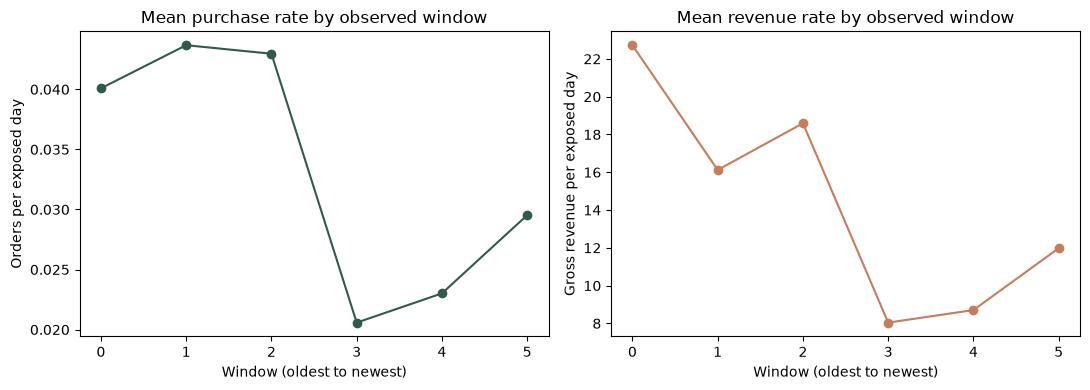

In [3]:
cutoffs_30 = HORIZON_SPLIT_SPECS[30]
matrices = {}
trajectory_features = {}
curve_tables = {}
for role, cutoff in cutoffs_30.items():
    matrix_started = time.perf_counter()
    matrix = build_customer_trajectory_matrix(orders, cutoff, config.window_days, config.lookback_days)
    profile_timings_ms['trajectory_matrix_construction_ms'] += (time.perf_counter() - matrix_started) * 1000
    feature_started = time.perf_counter()
    features = calculate_trajectory_features(matrix, config)
    profile_timings_ms['feature_engineering_ms'] += (time.perf_counter() - feature_started) * 1000
    matrices[role.upper()] = matrix
    trajectory_features[role.upper()] = features
    curve_tables[role.upper()] = build_trajectory_curve_table(matrix, features)

print('30-day TRAIN / VAL / TEST rows:', {role: len(frame) for role, frame in trajectory_features.items()})
display(trajectory_features['TEST']['history_sufficiency'].value_counts().rename_axis('history_sufficiency').to_frame('customers'))

population_purchase = matrices['TEST'].groupby('window_index')['purchase_rate_per_observed_day'].mean()
population_revenue = matrices['TEST'].groupby('window_index')['revenue_rate_per_observed_day'].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(population_purchase.index, population_purchase.values, marker='o', color='#315a4c')
axes[0].set(title='Mean purchase rate by observed window', xlabel='Window (oldest to newest)', ylabel='Orders per exposed day')
axes[1].plot(population_revenue.index, population_revenue.values, marker='o', color='#c57d5c')
axes[1].set(title='Mean revenue rate by observed window', xlabel='Window (oldest to newest)', ylabel='Gross revenue per exposed day')
fig.tight_layout()
plt.show()

## 8. TRAIN-only preprocessing and candidate clustering
## 9. Cluster-quality evaluation
## 10. Cluster stability and sensitivity
## 11. Comparison with static RFM segmentation
Candidate counts are limited to 2–6. Imputation, scaling, and cluster centers are fitted on TRAIN only. Validation silhouette and repeated TRAIN stability checks are reported; cluster identifiers are arbitrary. A candidate is not promoted as a reusable trajectory segmentation unless every cluster contains at least 5% of eligible TRAIN and VAL customers; tiny partitions are treated as rare-outlier groups, not validated customer segments.

Shape clustering has its own stricter eligibility rule: all six historical windows must be observed, at least two windows must contain purchases, and at least one completed interpurchase gap must be available strictly before the cutoff. This support rule is separate from summary-trajectory and functional-analysis eligibility.

In [4]:
cluster_candidates = []
cluster_bundles = {}
train_cluster_features = trajectory_features['TRAIN']
val_cluster_features = trajectory_features['VAL']
for cluster_count in range(2, 7):
    candidate_config = TrajectoryClusteringConfig(n_clusters=cluster_count, stability_runs=8, n_init=15)
    prepared_train = prepare_trajectory_features(train_cluster_features, candidate_config)
    fit_started = time.perf_counter()
    fitted = fit_trajectory_clusters(prepared_train, candidate_config)
    profile_timings_ms['clustering_fit_ms'] += (time.perf_counter() - fit_started) * 1000
    stability_started = time.perf_counter()
    stability = evaluate_cluster_stability(prepared_train, fitted, candidate_config)
    profile_timings_ms['cluster_stability_evaluation_ms'] += (time.perf_counter() - stability_started) * 1000
    prepared_val = prepare_trajectory_features(val_cluster_features, candidate_config)
    assignment_started = time.perf_counter()
    val_assignment = assign_trajectory_clusters(fitted, prepared_val)
    val_scaled = transform_trajectory_features(fitted['transform'], prepared_val)
    profile_timings_ms['cluster_assignment_ms'] += (time.perf_counter() - assignment_started) * 1000
    val_mask = val_scaled['transform_status'].eq('transformed')
    val_values = val_scaled.loc[val_mask, [f'scaled_{name}' for name in candidate_config.feature_columns]].to_numpy()
    val_labels = val_assignment.loc[val_mask, 'trajectory_cluster_id'].astype(int).to_numpy()
    validation_silhouette = None
    if len(np.unique(val_labels)) > 1 and len(np.unique(val_labels)) < len(val_labels):
        from sklearn.metrics import silhouette_score
        validation_silhouette = float(silhouette_score(val_values, val_labels))
    train_sizes = {int(key): int(value) for key, value in stability['cluster_sizes'].items()}
    validation_sizes = {int(key): int(value) for key, value in pd.Series(val_labels).value_counts().items()}
    cluster_candidates.append({
        'n_clusters': cluster_count,
        'eligible_train': stability['eligible_train_customers'],
        'validation_assigned': int(val_mask.sum()),
        'cluster_sizes_validation': validation_sizes,
        'minimum_train_cluster_share': min(train_sizes.values()) / stability['eligible_train_customers'],
        'minimum_validation_cluster_share': min(validation_sizes.values()) / max(1, int(val_mask.sum())),
        'validation_silhouette': validation_silhouette,
        'train_silhouette': stability['silhouette_score'],
        'davies_bouldin_index': stability['davies_bouldin_index'],
        'calinski_harabasz_index': stability['calinski_harabasz_index'],
        'within_cluster_inertia': float(fitted['model'].inertia_),
        'seed_ari_mean': stability['seed_adjusted_rand_mean'],
        'seed_ari_min': stability['seed_adjusted_rand_min'],
        'resample_ari_mean': stability['resample_adjusted_rand_mean'],
        'resample_ari_min': stability['resample_adjusted_rand_min'],
        'cluster_sizes_train': stability['cluster_sizes'],
    })
    cluster_bundles[cluster_count] = fitted

cluster_candidate_table = pd.DataFrame(cluster_candidates)
display(cluster_candidate_table)
stable_candidates = cluster_candidate_table.loc[
    cluster_candidate_table['validation_silhouette'].notna()
    & cluster_candidate_table['seed_ari_mean'].ge(0.75)
    & cluster_candidate_table['resample_ari_mean'].ge(0.60)
    & cluster_candidate_table['minimum_train_cluster_share'].ge(0.05)
    & cluster_candidate_table['minimum_validation_cluster_share'].ge(0.05)
]
selected_cluster_count = None
selected_summary_bundle = None
cluster_status = 'not_supported_due_to_minimum_cluster_share_or_stability'
if not stable_candidates.empty:
    selected = stable_candidates.sort_values(['validation_silhouette', 'n_clusters'], ascending=[False, True]).iloc[0]
    selected_cluster_count = int(selected['n_clusters'])
    selected_summary_bundle = cluster_bundles[selected_cluster_count]
    cluster_status = 'selected_on_validation_and_train_stability'
print('Cluster model status:', cluster_status, 'selected k:', selected_cluster_count)

test_assignments = None
static_dynamic_comparison = {'comparable_customers': 0, 'normalized_mutual_information': None, 'adjusted_rand_index': None, 'cross_tabulation': [], 'status': 'no_validation_candidate'}
best_validation_candidates = cluster_candidate_table.loc[cluster_candidate_table['validation_silhouette'].notna()].sort_values(['validation_silhouette', 'n_clusters'], ascending=[False, True])
if not best_validation_candidates.empty:
    exploratory_k = int(best_validation_candidates.iloc[0]['n_clusters'])
    exploratory_bundle = cluster_bundles[exploratory_k]
    prepared_test = prepare_trajectory_features(trajectory_features['TEST'])
    exploratory_test_assignments = assign_trajectory_clusters(exploratory_bundle, prepared_test)
    saved_split = pd.read_csv(ROOT / 'data/processed/temporal/predictive_splits_30d.csv')
    static_test = saved_split.loc[saved_split['split_role'].eq('TEST'), ['Customer ID', 'Hist_Segment']]
    static_dynamic_comparison = compare_static_dynamic_segments(static_test, exploratory_test_assignments)
    static_dynamic_comparison['status'] = 'exploratory_best_validation_candidate_not_promoted'
    static_dynamic_comparison['candidate_cluster_count'] = exploratory_k
    display(pd.DataFrame(static_dynamic_comparison['cross_tabulation']))
shape_features_started = time.perf_counter()
shape_train = build_shape_trajectory_features(matrices['TRAIN'])
shape_val = build_shape_trajectory_features(matrices['VAL'])
shape_test = build_shape_trajectory_features(matrices['TEST'])
profile_timings_ms['feature_engineering_ms'] += (time.perf_counter() - shape_features_started) * 1000
shape_feature_columns = tuple(column for column in shape_train if column.startswith('shape_window_'))
shape_train_eligible = int(shape_train['cluster_eligible'].sum())
shape_val_eligible = int(shape_val['cluster_eligible'].sum())
shape_candidate_max = min(6, shape_train_eligible - 1, int(shape_train_eligible * 0.8) - 1, shape_val_eligible - 1)
shape_cluster_candidates = []
shape_cluster_bundles = {}
for cluster_count in range(2, shape_candidate_max + 1):
    shape_config = TrajectoryClusteringConfig(
        feature_columns=shape_feature_columns, eligible_column='cluster_eligible',
        n_clusters=cluster_count, stability_runs=8, n_init=15
    )
    prepared_shape_train = prepare_trajectory_features(shape_train, shape_config)
    fit_started = time.perf_counter()
    shape_bundle = fit_trajectory_clusters(prepared_shape_train, shape_config)
    profile_timings_ms['clustering_fit_ms'] += (time.perf_counter() - fit_started) * 1000
    stability_started = time.perf_counter()
    shape_stability = evaluate_cluster_stability(prepared_shape_train, shape_bundle, shape_config)
    profile_timings_ms['cluster_stability_evaluation_ms'] += (time.perf_counter() - stability_started) * 1000
    prepared_shape_val = prepare_trajectory_features(shape_val, shape_config)
    assignment_started = time.perf_counter()
    shape_val_assignment = assign_trajectory_clusters(shape_bundle, prepared_shape_val)
    shape_val_scaled = transform_trajectory_features(shape_bundle['transform'], prepared_shape_val)
    profile_timings_ms['cluster_assignment_ms'] += (time.perf_counter() - assignment_started) * 1000
    shape_val_mask = shape_val_scaled['transform_status'].eq('transformed')
    shape_val_values = shape_val_scaled.loc[shape_val_mask, [f'scaled_{name}' for name in shape_feature_columns]].to_numpy()
    shape_val_labels = shape_val_assignment.loc[shape_val_mask, 'trajectory_cluster_id'].astype(int).to_numpy()
    shape_val_silhouette = None
    if len(np.unique(shape_val_labels)) > 1 and len(np.unique(shape_val_labels)) < len(shape_val_labels):
        from sklearn.metrics import silhouette_score
        shape_val_silhouette = float(silhouette_score(shape_val_values, shape_val_labels))
    shape_train_sizes = pd.Series({int(key): int(value) for key, value in shape_stability['cluster_sizes'].items()}, dtype=int).reindex(range(cluster_count), fill_value=0).to_dict()
    shape_val_sizes = pd.Series(shape_val_labels).value_counts().reindex(range(cluster_count), fill_value=0).astype(int).to_dict()
    shape_cluster_candidates.append({
        'n_clusters': cluster_count, 'eligible_train': shape_stability['eligible_train_customers'],
        'validation_assigned': int(shape_val_mask.sum()), 'eligible_validation': shape_val_eligible, 'cluster_sizes_train': shape_stability['cluster_sizes'],
        'cluster_sizes_validation': shape_val_sizes,
        'minimum_train_cluster_share': min(shape_train_sizes.values()) / shape_stability['eligible_train_customers'],
        'minimum_validation_cluster_share': min(shape_val_sizes.values()) / max(1, int(shape_val_mask.sum())),
        'validation_silhouette': shape_val_silhouette,
        'train_silhouette': shape_stability['silhouette_score'],
        'within_cluster_inertia': float(shape_bundle['model'].inertia_),
        'davies_bouldin_index': shape_stability['davies_bouldin_index'],
        'calinski_harabasz_index': shape_stability['calinski_harabasz_index'],
        'seed_ari_mean': shape_stability['seed_adjusted_rand_mean'],
        'seed_ari_min': shape_stability['seed_adjusted_rand_min'],
        'resample_ari_mean': shape_stability['resample_adjusted_rand_mean'],
        'resample_ari_min': shape_stability['resample_adjusted_rand_min'],
        'resample_size': shape_stability['resample_size'],
    })
    shape_cluster_bundles[cluster_count] = shape_bundle
shape_cluster_candidate_table = pd.DataFrame(shape_cluster_candidates, columns=['n_clusters', 'eligible_train', 'validation_assigned', 'eligible_validation', 'cluster_sizes_train', 'cluster_sizes_validation', 'minimum_train_cluster_share', 'minimum_validation_cluster_share', 'validation_silhouette', 'train_silhouette', 'within_cluster_inertia', 'davies_bouldin_index', 'calinski_harabasz_index', 'seed_ari_mean', 'seed_ari_min', 'resample_ari_mean', 'resample_ari_min', 'resample_size'])
display(shape_cluster_candidate_table)
supported_shape_candidates = shape_cluster_candidate_table.loc[
    shape_cluster_candidate_table['validation_silhouette'].notna()
    & shape_cluster_candidate_table['seed_ari_mean'].ge(0.75)
    & shape_cluster_candidate_table['resample_ari_mean'].ge(0.60)
    & shape_cluster_candidate_table['minimum_train_cluster_share'].ge(0.05)
    & shape_cluster_candidate_table['minimum_validation_cluster_share'].ge(0.05)
]
selected_shape_cluster_count = None
selected_shape_bundle = None
shape_cluster_status = 'not_supported_due_to_insufficient_eligible_customers' if shape_candidate_max < 2 else 'not_supported_by_train_validation_stability'
if not supported_shape_candidates.empty:
    selected_shape = supported_shape_candidates.sort_values(['validation_silhouette', 'n_clusters'], ascending=[False, True]).iloc[0]
    selected_shape_cluster_count = int(selected_shape['n_clusters'])
    selected_shape_bundle = shape_cluster_bundles[selected_shape_cluster_count]
    shape_cluster_status = 'selected_on_validation_train_stability_and_minimum_support'
shape_test_assignments = None
shape_static_dynamic_comparison = {'comparable_customers': 0, 'normalized_mutual_information': None, 'adjusted_rand_index': None, 'cross_tabulation': [], 'status': 'no_supported_shape_cluster_model'}
if selected_shape_bundle is not None:
    shape_test_config = TrajectoryClusteringConfig(**{**selected_shape_bundle['config'], 'feature_columns': tuple(selected_shape_bundle['config']['feature_columns'])})
    prepared_shape_test = prepare_trajectory_features(shape_test, shape_test_config)
    assignment_started = time.perf_counter()
    shape_test_assignments = assign_trajectory_clusters(selected_shape_bundle, prepared_shape_test)
    profile_timings_ms['cluster_assignment_ms'] += (time.perf_counter() - assignment_started) * 1000
    saved_split = pd.read_csv(ROOT / 'data/processed/temporal/predictive_splits_30d.csv')
    static_test = saved_split.loc[saved_split['split_role'].eq('TEST'), ['Customer ID', 'Hist_Segment']]
    shape_static_dynamic_comparison = compare_static_dynamic_segments(static_test, shape_test_assignments)
    display(pd.DataFrame(shape_static_dynamic_comparison['cross_tabulation']))
test_assignments = shape_test_assignments if shape_test_assignments is not None else exploratory_test_assignments if not best_validation_candidates.empty else None
print('Shape-cluster eligible customers by role:', {'TRAIN': shape_train_eligible, 'VAL': shape_val_eligible, 'TEST': int(shape_test['cluster_eligible'].sum())})
print('Shape support requires all six observed windows, at least two purchase-active windows, and one completed pre-cutoff interpurchase gap.')
print('Shape cluster model status:', shape_cluster_status, 'selected k:', selected_shape_cluster_count)
print('Shape standardization is per customer; constant curves map to zero and remain interpretable as no relative shape variation.')

,n_clusters,eligible_train,validation_assigned,cluster_sizes_validation,minimum_train_cluster_share,minimum_validation_cluster_share,validation_silhouette,train_silhouette,davies_bouldin_index,calinski_harabasz_index,within_cluster_inertia,seed_ari_mean,seed_ari_min,resample_ari_mean,resample_ari_min,cluster_sizes_train
0,2,1130,1291,"{0: 1278, 1: 13}",0.019469,0.010070,0.801456,0.837591,0.598212,838.988730,5832.143228,1.000000,1.000000,0.973168,0.934229,"{'0': 1108, '1': 22}"
1,3,1130,1291,"{1: 721, 0: 557, 2: 13}",0.019469,0.010070,0.345043,0.377136,0.933258,721.993055,4458.052090,1.000000,1.000000,0.986677,0.973896,"{'0': 477, '1': 631, '2': 22}"
2,4,1130,1291,"{1: 720, 0: 557, 3: 12, 2: 2}",0.001770,0.001549,0.347756,0.380343,0.831729,713.109970,3506.971827,1.000000,1.000000,0.988306,0.975936,"{'0': 477, '1': 630, '2': 2, '3': 21}"
3,5,1130,1291,"{0: 719, 3: 557, 1: 13, 2: 2}",0.000885,0.001549,0.348697,0.381471,0.703425,663.931365,3026.213365,1.000000,1.000000,0.850083,0.434726,"{'0': 630, '1': 20, '2': 2, '3': 477, '4': 1}"
4,6,1130,1291,"{1: 811, 0: 370, 4: 95, 2: 13, 3: 2}",0.000885,0.001549,0.361908,0.417000,0.667678,652.609764,2605.642305,0.679211,0.400058,0.656348,0.551362,"{'0': 309, '1': 734, '2': 20, '3': 2, '4': 64,..."


Cluster model status: not_supported_due_to_minimum_cluster_share_or_stability selected k: None


,static_segment,trajectory_cluster_id,customers
0,Lapsed / At-Risk,0,264
1,Lapsed / At-Risk,1,7
2,Recent / Active,0,1028
3,Recent / Active,1,7


,n_clusters,eligible_train,validation_assigned,eligible_validation,cluster_sizes_train,cluster_sizes_validation,minimum_train_cluster_share,minimum_validation_cluster_share,validation_silhouette,train_silhouette,within_cluster_inertia,davies_bouldin_index,calinski_harabasz_index,seed_ari_mean,seed_ari_min,resample_ari_mean,resample_ari_min,resample_size
0,2,679,980,980,"{'0': 402, '1': 277}","{0: 576, 1: 404}",0.407953,0.412245,0.145487,0.177707,3405.646576,2.134785,132.860312,0.548835,0.448249,0.562420,0.426381,543
1,3,679,980,980,"{'0': 188, '1': 234, '2': 257}","{0: 330, 1: 268, 2: 382}",0.276878,0.273469,0.142276,0.193711,2907.272857,1.771452,135.643881,0.798309,0.397351,0.797994,0.339440,543
2,4,679,980,980,"{'0': 162, '1': 210, '2': 161, '3': 146}","{0: 221, 1: 290, 2: 297, 3: 172}",0.215022,0.175510,0.165123,0.210818,2546.082907,1.529535,135.023626,0.601069,0.459235,0.580660,0.375219,543
3,5,679,980,980,"{'0': 138, '1': 136, '2': 162, '3': 86, '4': 157}","{0: 173, 1: 205, 2: 253, 3: 222, 4: 127}",0.126657,0.129592,0.155376,0.216876,2268.270352,1.415372,134.139850,0.387053,0.364070,0.471990,0.378561,543
4,6,679,980,980,"{'0': 121, '1': 119, '2': 127, '3': 126, '4': ...","{0: 107, 1: 120, 2: 163, 3: 147, 4: 339, 5: 104}",0.091311,0.106122,0.138271,0.228101,2016.071912,1.299156,137.394464,0.799932,0.634707,0.646987,0.481461,543


,static_segment,trajectory_cluster_id,customers
0,Lapsed / At-Risk,0,24
1,Lapsed / At-Risk,1,47
2,Lapsed / At-Risk,2,98
3,Recent / Active,0,292
4,Recent / Active,1,274
5,Recent / Active,2,365


Shape-cluster eligible customers by role: {'TRAIN': 679, 'VAL': 980, 'TEST': 1100}
Shape support requires all six observed windows, at least two purchase-active windows, and one completed pre-cutoff interpurchase gap.
Shape cluster model status: selected_on_validation_train_stability_and_minimum_support selected k: 3
Shape standardization is per customer; constant curves map to zero and remain interpretable as no relative shape variation.


## 12. Functional curve representations
## 13. Functional PCA
## 14. Component interpretation and reconstruction
The method is a conservative PCA approximation on a common discrete grid, not a specialized functional-data estimator. Optional moving-average smoothing is selected on VAL reconstruction error only. Explained-variance ratios come from the TRAIN-fitted PCA and are reported as TRAIN explained variance. Held-out TEST contributes a separate reconstruction RMSE; no TEST explained-variance claim is made.

In [5]:
curve_columns = tuple(f'window_{index}' for index in range(config.window_count))
functional_candidates = []
functional_bundles = {}
functional_status = 'not_supported_due_to_insufficient_train_curves'
selected_functional_bundle = None
functional_scores_by_role = {}
functional_test_scores = pd.DataFrame(columns=['Customer ID'])
functional_evaluation = {'method': 'not_fitted', 'evaluated_curves': 0, 'limitations': ['insufficient_train_or_validation_support']}
if int(curve_tables['TRAIN']['functional_eligible'].sum()) >= 30:
    for smoothing in ('none', 'moving_average'):
        for component_count in (1, 2, 3):
            functional_config = FunctionalTrajectoryConfig(
                curve_columns=curve_columns,
                max_components=component_count,
                smoothing_method=smoothing,
                min_train_curves=30,
            )
            try:
                functional_fit_started = time.perf_counter()
                fitted_functional = fit_functional_representation(curve_tables['TRAIN'], functional_config)
                profile_timings_ms['functional_fit_ms'] += (time.perf_counter() - functional_fit_started) * 1000
                validation_eval_started = time.perf_counter()
                validation_result = evaluate_functional_representation(fitted_functional, curve_tables['VAL'], evaluation_role='VAL')
                profile_timings_ms['functional_curve_evaluation_ms'] += (time.perf_counter() - validation_eval_started) * 1000
                functional_candidates.append({
                    'smoothing_method': smoothing,
                    'component_count': fitted_functional['pca'].n_components_,
                    'train_curves': fitted_functional['fit_customer_count'],
                    'validation_curves': validation_result['evaluated_curves'],
                    'validation_reconstruction_rmse': validation_result['val_reconstruction_rmse'],
                    'train_explained_variance': float(fitted_functional['train_explained_variance_ratio'].sum()),
                })
                functional_bundles[(smoothing, component_count)] = fitted_functional
            except ValueError as error:
                functional_candidates.append({'smoothing_method': smoothing, 'component_count': component_count, 'status': str(error)})
    functional_candidate_table = pd.DataFrame(functional_candidates)
    display(functional_candidate_table)
    valid_functional = functional_candidate_table.dropna(subset=['validation_reconstruction_rmse']).copy()
    if not valid_functional.empty:
        best_validation_rmse = float(valid_functional['validation_reconstruction_rmse'].min())
        within_tolerance = valid_functional.loc[valid_functional['validation_reconstruction_rmse'].le(best_validation_rmse * 1.05)]
        selected_row = within_tolerance.sort_values(['component_count', 'validation_reconstruction_rmse', 'smoothing_method']).iloc[0]
        selected_smoothing = str(selected_row['smoothing_method'])
        selected_component_count = int(selected_row['component_count'])
        selected_functional_bundle = functional_bundles[(selected_smoothing, selected_component_count)]
        functional_transform_started = time.perf_counter()
        functional_scores_by_role = {
            role: transform_functional_representation(selected_functional_bundle, curve_tables[role])
            for role in ('TRAIN', 'VAL', 'TEST')
        }
        profile_timings_ms['functional_transform_ms'] = (time.perf_counter() - functional_transform_started) * 1000
        functional_test_scores = functional_scores_by_role['TEST']
        functional_eval_started = time.perf_counter()
        functional_evaluation = evaluate_functional_representation(selected_functional_bundle, curve_tables['TEST'], evaluation_role='TEST')
        profile_timings_ms['functional_curve_evaluation_ms'] += (time.perf_counter() - functional_eval_started) * 1000
        functional_evaluation['selected_component_count'] = selected_component_count
        functional_evaluation['component_selection_rule'] = 'Choose the fewest components whose VAL reconstruction RMSE is within 5% of the best candidate.'
        stability_started = time.perf_counter()
        functional_evaluation['component_stability'] = evaluate_functional_component_stability(
            curve_tables['TRAIN'], selected_functional_bundle, random_state=42, n_resamples=50
        )
        profile_timings_ms['functional_stability_evaluation_ms'] = (time.perf_counter() - stability_started) * 1000
        functional_status = 'grid_based_pca_fitted_on_train'
        print('VAL-selected smoothing:', selected_smoothing)
        print('VAL-selected component count:', selected_component_count)
        print('Held-out TEST reconstruction RMSE is a one-time descriptive evaluation:', functional_evaluation['test_reconstruction_rmse'])
    else:
        functional_status = 'not_supported_due_to_validation_support'
else:
    print('Functional PCA was not fit: fewer than 30 eligible TRAIN curves.')
print('FDA status:', functional_status)

,smoothing_method,component_count,train_curves,validation_curves,validation_reconstruction_rmse,train_explained_variance
0,none,1,480,590,0.054783,0.671582
1,none,2,480,590,0.044951,0.768386
2,none,3,480,590,0.035647,0.840378
3,moving_average,1,480,590,0.034892,0.871676
4,moving_average,2,480,590,0.016860,0.954325
5,moving_average,3,480,590,0.006668,0.988213


VAL-selected smoothing: moving_average
VAL-selected component count: 3
Held-out TEST reconstruction RMSE is a one-time descriptive evaluation: 0.006248220100680978
FDA status: grid_based_pca_fitted_on_train


## 15. Historical purchasing patterns across trajectory groups
## 16. Future purchase outcome associations
Associations use frozen TEST assignments and fully matured 30-, 60-, and 90-day future windows. These are retrospective associations, not causal effects or permanent churn labels.

In [6]:
offline_evaluation_started = time.perf_counter()
cluster_association_results = {
    'status': 'not_available_without_stable_clusters',
    'horizons': {},
    'limitations': ['No stable TRAIN/VAL-selected summary cluster model was available.'],
}
outcomes_by_horizon = {}
test_ids = trajectory_features['TEST']['Customer ID'].astype(int).tolist()
for horizon in (30, 60, 90):
    outcomes_by_horizon[horizon] = build_future_purchase_outcomes(
        orders, test_ids, cutoff_test, horizon, dataset_end
    )
if test_assignments is not None:
    cluster_association_results = analyze_future_purchase_associations(
        trajectory_features['TEST'],
        test_assignments,
        outcomes_by_horizon,
        n_bootstrap=1000,
    )
    for horizon, result in cluster_association_results['horizons'].items():
        print(f'{horizon}-day associations; TEST assigned customers = {result["evaluated_assigned_customers"]:,}')
        display(pd.DataFrame(result['clusters']))
else:
    print('No cluster association is estimated without a TRAIN/VAL-supported frozen solution.')
association_feature_columns = tuple(
    name for name in (
        'purchase_rate_slope_per_window', 'revenue_rate_slope_per_window',
        'purchase_rate_recent_minus_early', 'revenue_rate_recent_minus_early',
        'purchase_rate_volatility', 'revenue_rate_volatility',
        'active_purchase_windows', 'longest_observed_inactive_run',
        'completed_gap_slope_days_per_gap'
    ) if name in trajectory_features['TEST']
)
feature_association_results = analyze_trajectory_feature_outcome_associations(
    trajectory_features['TEST'], outcomes_by_horizon,
    feature_columns=association_feature_columns, n_bootstrap=1000
)
for horizon, result in feature_association_results['horizons'].items():
    print(f'{horizon}-day feature associations; cohort={result["cohort_customers"]:,}')
    display(pd.DataFrame(result['feature_associations']))
association_results = {
    'cluster_associations': cluster_association_results,
    'trajectory_feature_associations': feature_association_results,
}

30-day associations; TEST assigned customers = 1,100


,trajectory_cluster_id,customer_count,future_purchase_rate,future_nonpurchase_rate,comparison_future_purchase_rate,purchase_rate_difference_vs_other_clusters,difference_ci_95,fisher_exact_p_value,mean_history_length_days,median_history_recency_days,mean_purchase_probability,mean_personalized_expected_revenue_gbp,fdr_adjusted_q_value
0,0,316,0.487342,0.512658,0.468112,0.019230,"[-0.049409, 0.084555]",0.593592,237.242018,None,None,None,0.593592
1,1,321,0.433022,0.566978,0.490372,-0.057350,"[-0.116031, 0.005696]",0.084696,230.217904,None,None,None,0.254088
2,2,463,0.492441,0.507559,0.459969,0.032472,"[-0.026233, 0.089831]",0.298803,237.086236,None,None,None,0.448204


60-day associations; TEST assigned customers = 1,100


,trajectory_cluster_id,customer_count,future_purchase_rate,future_nonpurchase_rate,comparison_future_purchase_rate,purchase_rate_difference_vs_other_clusters,difference_ci_95,fisher_exact_p_value,mean_history_length_days,median_history_recency_days,mean_purchase_probability,mean_personalized_expected_revenue_gbp,fdr_adjusted_q_value
0,0,316,0.712025,0.287975,0.709184,0.002842,"[-0.056157, 0.061696]",0.941605,237.242018,None,None,None,0.941605
1,1,321,0.713396,0.286604,0.708601,0.004795,"[-0.055152, 0.06125]",0.884110,230.217904,None,None,None,0.941605
2,2,463,0.706263,0.293737,0.712716,-0.006452,"[-0.058888, 0.046948]",0.840110,237.086236,None,None,None,0.941605


90-day associations; TEST assigned customers = 1,100


,trajectory_cluster_id,customer_count,future_purchase_rate,future_nonpurchase_rate,comparison_future_purchase_rate,purchase_rate_difference_vs_other_clusters,difference_ci_95,fisher_exact_p_value,mean_history_length_days,median_history_recency_days,mean_purchase_probability,mean_personalized_expected_revenue_gbp,fdr_adjusted_q_value
0,0,316,0.825949,0.174051,0.799745,0.026204,"[-0.024528, 0.07638]",0.353009,237.242018,None,None,None,0.729321
1,1,321,0.803738,0.196262,0.808729,-0.004991,"[-0.055048, 0.044686]",0.866594,230.217904,None,None,None,0.866594
2,2,463,0.796976,0.203024,0.814757,-0.017780,"[-0.066856, 0.031295]",0.486214,237.086236,None,None,None,0.729321


... (2 outputs left out)

60-day feature associations; cohort=3,373


,feature,eligible_customers,point_biserial_correlation,bootstrap_ci_95,p_value,fdr_adjusted_q_value
0,purchase_rate_slope_per_window,3037,0.062582,"[0.030489, 0.092831]",5.589736e-04,1.676921e-03
1,revenue_rate_slope_per_window,3037,0.036677,"[0.000758, 0.067508]",4.327038e-02,7.788668e-02
2,purchase_rate_recent_minus_early,2821,0.050731,"[0.016149, 0.082345]",7.038139e-03,1.583581e-02
3,revenue_rate_recent_minus_early,2821,0.032936,"[-0.002716, 0.061487]",8.028580e-02,1.204287e-01
4,purchase_rate_volatility,3037,-0.028041,"[-0.05841, 0.006947]",1.223457e-01,1.573016e-01
5,revenue_rate_volatility,3037,-0.002744,"[-0.032688, 0.036864]",8.798339e-01,8.935514e-01
6,active_purchase_windows,3373,0.378158,"[0.349366, 0.404193]",3.941328e-115,3.547196e-114
7,longest_observed_inactive_run,3373,-0.262492,"[-0.290106, -0.230652]",2.876484e-54,1.294418e-53
8,completed_gap_slope_days_per_gap,987,0.004265,"[-0.069335, 0.081927]",8.935514e-01,8.935514e-01


90-day feature associations; cohort=3,373


,feature,eligible_customers,point_biserial_correlation,bootstrap_ci_95,p_value,fdr_adjusted_q_value
0,purchase_rate_slope_per_window,3037,0.044999,"[0.01027, 0.079976]",1.313500e-02,3.206588e-02
1,revenue_rate_slope_per_window,3037,0.038365,"[0.002778, 0.069932]",3.449961e-02,5.174941e-02
2,purchase_rate_recent_minus_early,2821,0.046140,"[0.009854, 0.08167]",1.425150e-02,3.206588e-02
3,revenue_rate_recent_minus_early,2821,0.041387,"[0.00671, 0.070233]",2.793884e-02,5.028991e-02
4,purchase_rate_volatility,3037,-0.017607,"[-0.051496, 0.019986]",3.320549e-01,4.269277e-01
5,revenue_rate_volatility,3037,-0.012036,"[-0.042751, 0.030766]",5.073151e-01,5.707294e-01
6,active_purchase_windows,3373,0.356563,"[0.330076, 0.381982]",1.120099e-101,1.008089e-100
7,longest_observed_inactive_run,3373,-0.254522,"[-0.285032, -0.221374]",5.066571e-51,2.279957e-50
8,completed_gap_slope_days_per_gap,987,0.016854,"[-0.061074, 0.091419]",5.969108e-01,5.969108e-01


## 17. Chronological prediction experiment
## 18. Comparisons with Notebook 08 and Purchase Clock
The trajectory-only model is trained at the official 30-day TRAIN cutoff, selected on VAL, and evaluated once on TEST. Purchase Clock is reported on the identical eligible TEST subset as a standalone comparator only. The combined conditional model is not fitted because no saved Purchase Clock prediction vintage predates the official downstream TRAIN cutoff.

In [7]:
from src.customer_intelligence import CustomerIntelligence
from src.temporal_framework import compute_historical_features
from scipy.stats import spearmanr

static_behavior_features = {}
for role, cutoff in cutoffs_30.items():
    role_key = role.upper()
    static = compute_historical_features(orders, cutoff)
    behavior = compute_behavior_features(orders, cutoff)
    behavior_columns = [
        name for name in (
            'purchase_rate_ratio', 'revenue_rate_ratio', 'gap_deviation_score',
            'ewma_gap_change_days', 'personalized_delay_ratio'
        ) if name in behavior.columns
    ]
    assembled = trajectory_features[role_key].merge(
        static[['Customer ID', 'Recency', 'Frequency', 'Monetary_Gross']],
        on='Customer ID', how='left', validate='one_to_one'
    ).merge(
        behavior[['Customer ID', *behavior_columns]],
        on='Customer ID', how='left', validate='one_to_one'
    )
    static_behavior_features[role_key] = assembled
functional_score_relationships = []
if selected_functional_bundle is not None:
    functional_test_table = static_behavior_features['TEST'].merge(
        functional_scores_by_role['TEST'], on='Customer ID', how='inner', validate='one_to_one'
    )
    functional_test_table = functional_test_table.loc[
        functional_test_table['functional_analysis_status'].eq('scored')
    ]
    relationship_features = tuple(dict.fromkeys(('Recency', 'Frequency', 'Monetary_Gross', *behavior_columns)))
    for component in (name for name in functional_test_table if name.startswith('functional_component_')):
        for feature_name in relationship_features:
            if feature_name not in functional_test_table:
                continue
            pair = functional_test_table[[component, feature_name]].apply(pd.to_numeric, errors='coerce').dropna()
            if len(pair) < 30 or pair[component].nunique() < 2 or pair[feature_name].nunique() < 2:
                continue
            rho, p_value = spearmanr(pair[component], pair[feature_name])
            functional_score_relationships.append({
                'functional_component': component, 'existing_feature': feature_name,
                'eligible_customers': len(pair), 'spearman_rho': float(rho), 'p_value': float(p_value),
            })

for component in sorted({row['functional_component'] for row in functional_score_relationships}):
    component_rows = [index for index, row in enumerate(functional_score_relationships) if row['functional_component'] == component]
    p_values = np.asarray([functional_score_relationships[index]['p_value'] for index in component_rows], dtype=float)
    order = np.argsort(p_values)
    adjusted_sorted = np.minimum.accumulate((p_values[order] * len(p_values) / np.arange(1, len(p_values) + 1))[::-1])[::-1].clip(0, 1)
    adjusted = np.empty_like(adjusted_sorted)
    adjusted[order] = adjusted_sorted
    for position, index in enumerate(component_rows):
        functional_score_relationships[index]['fdr_adjusted_q_value'] = float(adjusted[position])

split_metrics = pd.read_csv(ROOT / 'data/processed/temporal/predictive_splits_30d.csv')
recency_columns = ('Recency',)
rfm_columns = ('Recency', 'Frequency', 'Monetary_Gross')
behavior_columns = tuple(behavior_columns)
trajectory_columns = tuple(name for name in DEFAULT_CLUSTER_FEATURES if name in static_behavior_features['TRAIN'])
model_feature_sets = {
    'recency baseline': recency_columns,
    'static RFM': rfm_columns,
    'Notebook 08 indicators': behavior_columns,
    'trajectory summary': trajectory_columns,
}
eligible_roles = {
    role: frame.loc[frame['eligible_for_summary_trajectory']].copy()
    for role, frame in static_behavior_features.items()
}
outcome_roles = {}
for role, cutoff in cutoffs_30.items():
    role_key = role.upper()
    ids = eligible_roles[role_key]['Customer ID'].astype(int).tolist()
    outcome_roles[role_key] = build_future_purchase_outcomes(orders, ids, cutoff, 30, dataset_end)

prediction_models = {}
prediction_rows = []
test_prediction_tables = {}
for model_name, columns in model_feature_sets.items():
    if not columns:
        continue
    fitted_model = fit_trajectory_purchase_model(
        eligible_roles['TRAIN'], outcome_roles['TRAIN'],
        eligible_roles['VAL'], outcome_roles['VAL'],
        feature_columns=columns,
    )
    test_prediction = predict_trajectory_purchase_probability(fitted_model, eligible_roles['TEST'])
    joined = test_prediction.merge(outcome_roles['TEST'], on='Customer ID', validate='one_to_one')
    metrics = compute_binary_prediction_metrics(
        joined['purchased_within_horizon'], joined['trajectory_purchase_probability']
    )
    prediction_models[model_name] = fitted_model
    test_prediction_tables[model_name] = joined
    prediction_rows.append({'model': model_name, 'selected_C': fitted_model['selected_C'], **metrics})

clock = CustomerIntelligence.from_artifacts(ROOT)
transactions = pd.read_csv(ROOT / 'data/processed/online_retail_cleaned_data.csv', parse_dates=['InvoiceDate'])
clock_ids = eligible_roles['TEST']['Customer ID'].astype(int).tolist()
clock_predictions = clock.predict_customers(
    transactions, cutoff_test, customer_ids=clock_ids, horizons=[30]
)
clock_joined = outcome_roles['TEST'].merge(clock_predictions[['Customer ID', 'purchase_probability_30d']], on='Customer ID', validate='one_to_one')
clock_metrics = compute_binary_prediction_metrics(
    clock_joined['purchased_within_horizon'], clock_joined['purchase_probability_30d']
)
prediction_rows.append({'model': 'saved Purchase Clock (same TEST subset)', 'selected_C': None, **clock_metrics})
prediction_table = pd.DataFrame(prediction_rows)
display(prediction_table)

functional_prediction_evaluation = {
    'status': 'not_available_without_supported_functional_representation',
    'models': [], 'paired_brier_differences': {}, 'test_customer_count': 0,
    'comparison_cohort': 'customers with complete, supported functional curves at each temporal cutoff',
}
functional_prediction_rows = []
functional_test_prediction_tables = {}
functional_clock_joined = None
if selected_functional_bundle is not None:
    functional_feature_columns = tuple(
        name for name in functional_test_scores
        if name.startswith('functional_component_')
    )
    functional_prediction_roles = {
        role: static_behavior_features[role].merge(
            functional_scores_by_role[role], on='Customer ID', how='inner', validate='one_to_one'
        ).loc[lambda frame: frame['functional_analysis_status'].eq('scored')].copy()
        for role in ('TRAIN', 'VAL', 'TEST')
    }
    functional_outcome_roles = {}
    for role, cutoff in cutoffs_30.items():
        role_key = role.upper()
        ids = functional_prediction_roles[role_key]['Customer ID'].astype(int).tolist()
        functional_outcome_roles[role_key] = build_future_purchase_outcomes(orders, ids, cutoff, 30, dataset_end)
    functional_model_feature_sets = {
        'recency baseline': recency_columns,
        'static RFM': rfm_columns,
        'Notebook 08 indicators': behavior_columns,
        'trajectory summary': trajectory_columns,
        'functional component scores': functional_feature_columns,
    }
    for model_name, columns in functional_model_feature_sets.items():
        if not columns:
            continue
        fitted_model = fit_trajectory_purchase_model(
            functional_prediction_roles['TRAIN'], functional_outcome_roles['TRAIN'],
            functional_prediction_roles['VAL'], functional_outcome_roles['VAL'],
            feature_columns=columns,
        )
        predicted = predict_trajectory_purchase_probability(
            fitted_model, functional_prediction_roles['TEST']
        )
        joined = predicted.merge(
            functional_outcome_roles['TEST'], on='Customer ID', validate='one_to_one'
        )
        metrics = compute_binary_prediction_metrics(
            joined['purchased_within_horizon'], joined['trajectory_purchase_probability']
        )
        functional_test_prediction_tables[model_name] = joined
        functional_prediction_rows.append({'model': model_name, 'selected_C': fitted_model['selected_C'], **metrics})
    functional_clock_ids = functional_prediction_roles['TEST']['Customer ID'].astype(int).tolist()
    functional_clock = clock.predict_customers(
        transactions, cutoff_test, customer_ids=functional_clock_ids, horizons=[30]
    )
    functional_clock_joined = functional_outcome_roles['TEST'].merge(
        functional_clock[['Customer ID', 'purchase_probability_30d']],
        on='Customer ID', validate='one_to_one'
    )
    functional_clock_metrics = compute_binary_prediction_metrics(
        functional_clock_joined['purchased_within_horizon'],
        functional_clock_joined['purchase_probability_30d'],
    )
    functional_prediction_rows.append({
        'model': 'saved Purchase Clock (same functional TEST subset)',
        'selected_C': None, **functional_clock_metrics,
    })
    functional_pca_test = functional_test_prediction_tables['functional component scores']
    functional_paired = {}
    for comparator in ('recency baseline', 'static RFM', 'Notebook 08 indicators', 'trajectory summary'):
        other = functional_test_prediction_tables[comparator][
            ['Customer ID', 'trajectory_purchase_probability']
        ].rename(columns={'trajectory_purchase_probability': 'comparison_probability'})
        paired = functional_pca_test[
            ['Customer ID', 'purchased_within_horizon', 'trajectory_purchase_probability']
        ].merge(other, on='Customer ID', validate='one_to_one')
        functional_paired[comparator] = paired_brier_difference_interval(
            paired['purchased_within_horizon'], paired['trajectory_purchase_probability'],
            paired['comparison_probability'], n_bootstrap=1000,
        )
    functional_clock_pair = functional_pca_test[
        ['Customer ID', 'purchased_within_horizon', 'trajectory_purchase_probability']
    ].merge(functional_clock_joined, on=['Customer ID', 'purchased_within_horizon'], validate='one_to_one')
    functional_paired['saved Purchase Clock'] = paired_brier_difference_interval(
        functional_clock_pair['purchased_within_horizon'],
        functional_clock_pair['trajectory_purchase_probability'],
        functional_clock_pair['purchase_probability_30d'], n_bootstrap=1000,
    )
    functional_prediction_evaluation = {
        'status': 'evaluated_on_functional_eligible_subset',
        'models': functional_prediction_rows,
        'paired_brier_differences': functional_paired,
        'test_customer_count': len(functional_pca_test),
        'train_customer_count': len(functional_prediction_roles['TRAIN']),
        'validation_customer_count': len(functional_prediction_roles['VAL']),
        'comparison_cohort': 'identical supported functional customers for every TEST comparator',
        'interpretation': 'Standalone same-cohort comparison only; not conditional incremental value beyond Purchase Clock.',
    }
    display(pd.DataFrame(functional_prediction_rows))

trajectory_test = test_prediction_tables.get('trajectory summary')
paired_comparisons = {}
if trajectory_test is not None:
    for comparator in ('recency baseline', 'static RFM', 'Notebook 08 indicators', 'saved Purchase Clock (same TEST subset)'):
        if comparator == 'saved Purchase Clock (same TEST subset)':
            paired = trajectory_test[['Customer ID', 'purchased_within_horizon', 'trajectory_purchase_probability']].merge(
                clock_joined[['Customer ID', 'purchase_probability_30d']], on='Customer ID', validate='one_to_one'
            )
            second = paired['purchase_probability_30d']
        elif comparator in test_prediction_tables:
            other = test_prediction_tables[comparator][['Customer ID', 'trajectory_purchase_probability']].rename(
                columns={'trajectory_purchase_probability': 'comparison_probability'}
            )
            paired = trajectory_test[['Customer ID', 'purchased_within_horizon', 'trajectory_purchase_probability']].merge(other, on='Customer ID', validate='one_to_one')
            second = paired['comparison_probability']
        else:
            continue
        paired_comparisons[comparator] = paired_brier_difference_interval(
            paired['purchased_within_horizon'],
            paired['trajectory_purchase_probability'], second, n_bootstrap=1000
        )

clock_metadata = json.loads((ROOT / 'models/purchase_clock/metadata.json').read_text())
vintage_report = assess_purchase_clock_vintage_availability(clock_metadata)
print('Incremental Purchase Clock + trajectory experiment:', vintage_report['incremental_purchase_clock_plus_trajectory'])
print('Standalone same-cohort TEST comparisons do not estimate conditional incremental value.')
profile_timings_ms['offline_evaluation_ms'] = (time.perf_counter() - offline_evaluation_started) * 1000

,model,selected_C,customer_count,positive_rate,roc_auc,average_precision,brier_score,log_loss,mean_predicted_probability,calibration_in_the_large_absolute_error,expected_calibration_error_10_bins,top_10_percent_customers,top_10_percent_precision,top_10_percent_recall
0,recency baseline,1.0,1306,0.446401,0.554675,0.486529,0.245697,0.684546,0.420448,0.025953,0.028630,131,0.511450,0.114923
1,static RFM,0.1,1306,0.446401,0.664401,0.633201,0.226263,0.656955,0.482197,0.035796,0.035796,131,0.793893,0.178388
2,Notebook 08 indicators,10.0,1306,0.446401,0.552757,0.491662,0.244964,0.684256,0.429996,0.016405,0.025254,131,0.557252,0.125214
3,trajectory summary,0.1,1306,0.446401,0.671528,0.618292,0.227122,0.647293,0.420774,0.025627,0.048028,131,0.725191,0.162950
4,saved Purchase Clock (same TEST subset),NaN,1306,0.446401,0.678118,0.648349,0.231091,0.664994,0.529257,0.082856,0.096291,131,0.786260,0.176672


,model,selected_C,customer_count,positive_rate,roc_auc,average_precision,brier_score,log_loss,mean_predicted_probability,calibration_in_the_large_absolute_error,expected_calibration_error_10_bins,top_10_percent_customers,top_10_percent_precision,top_10_percent_recall
0,recency baseline,10.0,659,0.578149,0.505783,0.596666,0.245376,0.683861,0.559292,0.018857,0.018857,66,0.651515,0.112861
1,static RFM,1.0,659,0.578149,0.643205,0.719905,0.229985,0.672542,0.623427,0.045278,0.045278,66,0.893939,0.154856
2,Notebook 08 indicators,0.1,659,0.578149,0.557351,0.605252,0.245269,0.695458,0.561747,0.016402,0.050155,66,0.530303,0.091864
3,trajectory summary,0.1,659,0.578149,0.627240,0.681476,0.234981,0.667703,0.564299,0.013850,0.040646,66,0.757576,0.131234
4,functional component scores,10.0,659,0.578149,0.646783,0.709012,0.230939,0.663072,0.592076,0.013927,0.053741,66,0.818182,0.141732
5,saved Purchase Clock (same functional TEST sub...,NaN,659,0.578149,0.657037,0.729129,0.235356,0.683854,0.655668,0.077520,0.097583,66,0.878788,0.152231


Incremental Purchase Clock + trajectory experiment: not_fitted_due_to_vintage_unavailability
Standalone same-cohort TEST comparisons do not estimate conditional incremental value.


## 19. Coverage, uncertainty, and subgroup analysis
Customer-level bootstrap intervals and Benjamini–Hochberg adjustment are reported for cluster/outcome associations. Predictive methods use the same trajectory-eligible TEST customers; results are not extrapolated to the full 3,373-customer cohort.

## 20. Research limitations
The observation period is short and left-truncated; sparse customers cannot support full curves. Clusters are descriptive, not risk ranks. Purchase nonreturn within a finite horizon is not permanent churn. TEST is used only after method and model selection are frozen.

## 21. Final hypothesis assessment
Each conclusion is generated from the corresponding executed evaluation. Unsupported or unstable methods remain unresolved; no causal claim is made.

### Integration with the wider research project
Notebook 11 builds on the interpurchase-time analysis (03), static K-means segments (04), and temporal validation framework (05). It compares new longitudinal evidence with the saved Purchase Clock (06), spending forecasts (07), Notebook 08 behavioral-change indicators, Notebook 09 reliability evaluation, and Notebook 10 revenue-at-risk prioritization. It does not rewrite their metrics or saved model artifacts. The next evidence needed is longer, less left-truncated customer history with confirmed acquisition dates and independently recorded retention interventions, so temporal patterns can be tested across multiple future cohorts.

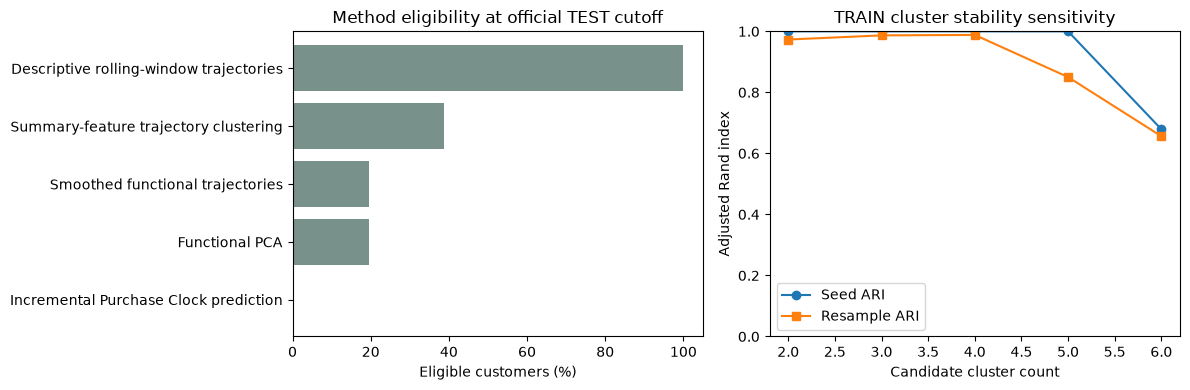

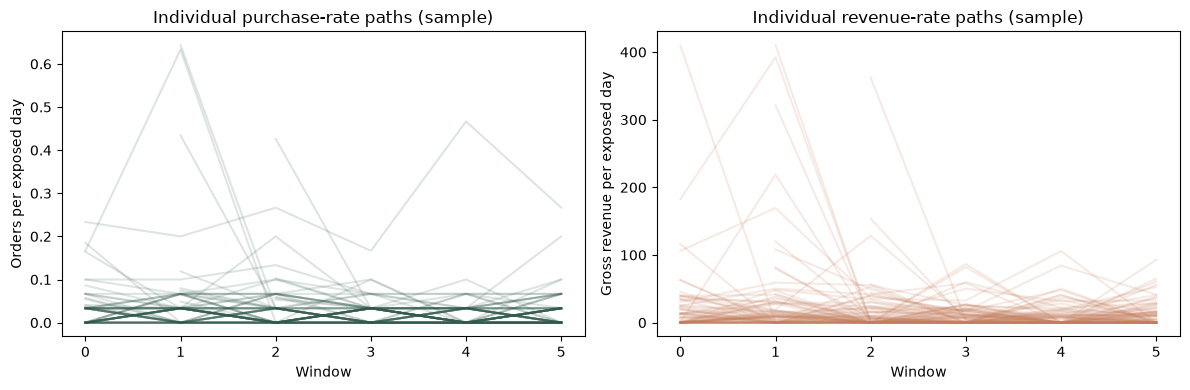

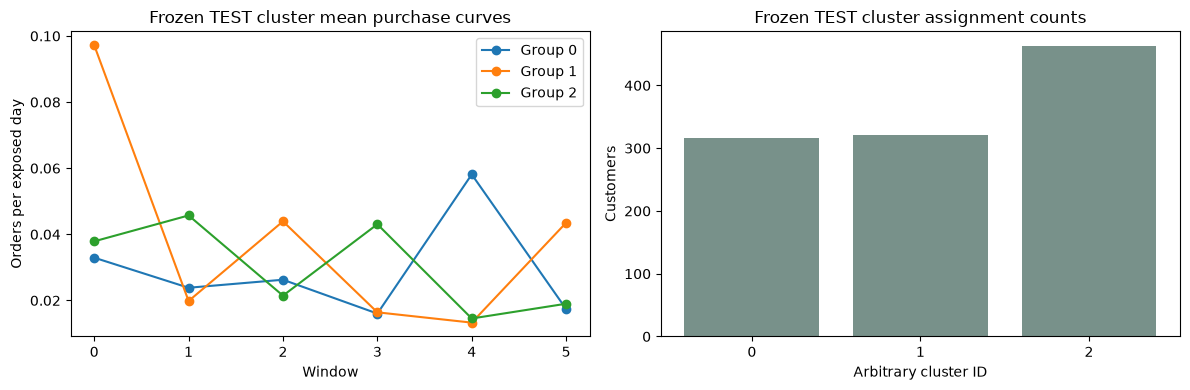

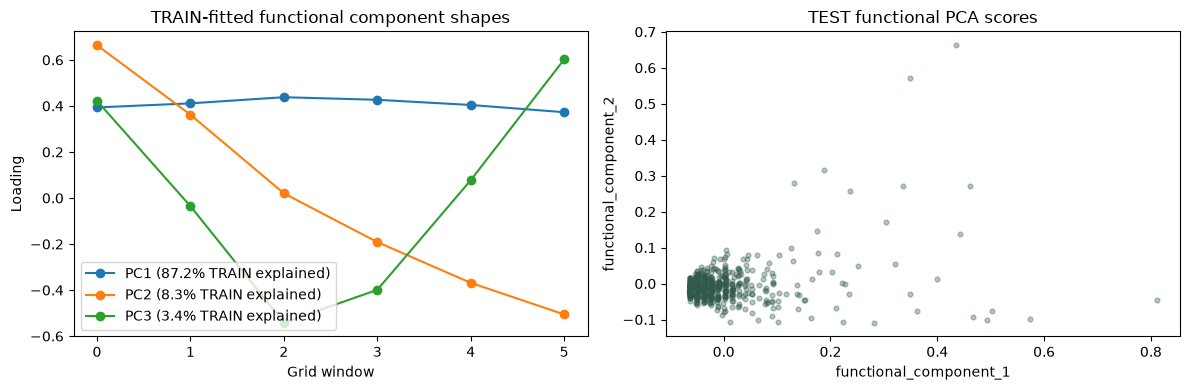

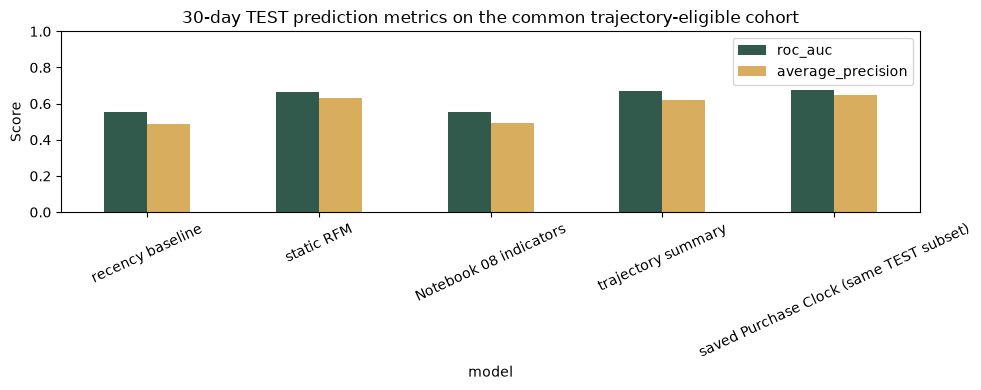

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coverage = test_feasibility.sort_values('coverage_percentage', ascending=False)
axes[0].barh(coverage['method'], coverage['coverage_percentage'], color='#78918a')
axes[0].set(title='Method eligibility at official TEST cutoff', xlabel='Eligible customers (%)')
axes[0].invert_yaxis()
axes[1].plot(cluster_candidate_table['n_clusters'], cluster_candidate_table['seed_ari_mean'], marker='o', label='Seed ARI')
axes[1].plot(cluster_candidate_table['n_clusters'], cluster_candidate_table['resample_ari_mean'], marker='s', label='Resample ARI')
axes[1].set(title='TRAIN cluster stability sensitivity', xlabel='Candidate cluster count', ylabel='Adjusted Rand index', ylim=(0, 1))
axes[1].legend()
fig.tight_layout()
plt.show()

eligible_test_ids = trajectory_features['TEST'].loc[
    trajectory_features['TEST']['eligible_for_summary_trajectory'], 'Customer ID'
].head(80)
sample_matrix = matrices['TEST'].loc[matrices['TEST']['Customer ID'].isin(eligible_test_ids)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for customer_id, group in sample_matrix.groupby('Customer ID'):
    axes[0].plot(group['window_index'], group['purchase_rate_per_observed_day'], alpha=0.16, color='#315a4c')
    axes[1].plot(group['window_index'], group['revenue_rate_per_observed_day'], alpha=0.16, color='#c57d5c')
axes[0].set(title='Individual purchase-rate paths (sample)', xlabel='Window', ylabel='Orders per exposed day')
axes[1].set(title='Individual revenue-rate paths (sample)', xlabel='Window', ylabel='Gross revenue per exposed day')
fig.tight_layout()
plt.show()

if (selected_summary_bundle is not None or selected_shape_bundle is not None) and test_assignments is not None:
    test_with_clusters = trajectory_features['TEST'].merge(test_assignments, on='Customer ID', validate='one_to_one')
    plot_data = matrices['TEST'].merge(test_with_clusters[['Customer ID', 'trajectory_cluster_id']], on='Customer ID', how='inner')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for cluster_id, group in plot_data.groupby('trajectory_cluster_id'):
        means = group.groupby('window_index')['purchase_rate_per_observed_day'].mean()
        axes[0].plot(means.index, means.values, marker='o', label=f'Group {int(cluster_id)}')
    sizes = test_assignments['trajectory_cluster_id'].value_counts().sort_index()
    axes[1].bar(sizes.index.astype(str), sizes.values, color='#78918a')
    axes[0].set(title='Frozen TEST cluster mean purchase curves', xlabel='Window', ylabel='Orders per exposed day')
    axes[0].legend()
    axes[1].set(title='Frozen TEST cluster assignment counts', xlabel='Arbitrary cluster ID', ylabel='Customers')
    fig.tight_layout()
    plt.show()
else:
    print('Cluster centroid and size plots omitted: no cluster solution passed the predeclared TRAIN/VAL checks.')

if selected_functional_bundle is not None:
    pca = selected_functional_bundle['pca']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for index, component in enumerate(pca.components_):
        axes[0].plot(range(len(component)), component, marker='o', label=f'PC{index + 1} ({pca.explained_variance_ratio_[index]:.1%} TRAIN explained)')
    score_columns = [name for name in functional_test_scores if name.startswith('functional_component_')]
    if len(score_columns) >= 2:
        scored = functional_test_scores.dropna(subset=score_columns[:2])
        axes[1].scatter(scored[score_columns[0]], scored[score_columns[1]], s=12, alpha=0.35, color='#315a4c')
        axes[1].set(xlabel=score_columns[0], ylabel=score_columns[1])
    axes[0].set(title='TRAIN-fitted functional component shapes', xlabel='Grid window', ylabel='Loading')
    axes[0].legend()
    axes[1].set_title('TEST functional PCA scores')
    fig.tight_layout()
    plt.show()
else:
    print('Functional component and score plots omitted: functional method was not supported.')

if not prediction_table.empty:
    fig, ax = plt.subplots(figsize=(10, 4))
    prediction_table.set_index('model')[['roc_auc', 'average_precision']].plot(kind='bar', ax=ax, color=['#315a4c', '#d8ad5e'])
    ax.set(title='30-day TEST prediction metrics on the common trajectory-eligible cohort', ylabel='Score', ylim=(0, 1))
    ax.tick_params(axis='x', rotation=25)
    fig.tight_layout()
    plt.show()

## 22. Versioned artifact export and reproducibility
Only a cluster model passing the prespecified TRAIN stability and VAL silhouette screen is exported. Functional PCA is saved only when eligible TRAIN and VAL curves support a frozen transform. The Purchase Clock and spending forecast artifacts are read-only.

In [9]:
import joblib

model_dir = ROOT / 'models/trajectory_analysis'
metrics_dir = ROOT / 'data/metrics'
model_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)
summary_model_path = model_dir / 'summary_clusters.joblib'
shape_model_path = model_dir / 'shape_clusters.joblib'
functional_model_path = model_dir / 'functional_pca.joblib'
if selected_summary_bundle is not None:
    joblib.dump(selected_summary_bundle, summary_model_path)
elif summary_model_path.exists():
    summary_model_path.unlink()
if selected_shape_bundle is not None:
    joblib.dump(selected_shape_bundle, shape_model_path)
elif shape_model_path.exists():
    shape_model_path.unlink()
if selected_functional_bundle is not None:
    joblib.dump(selected_functional_bundle, functional_model_path)
elif functional_model_path.exists():
    functional_model_path.unlink()

cluster_model_status = shape_cluster_status if selected_shape_bundle is not None else cluster_status
cluster_model_count = selected_shape_cluster_count if selected_shape_bundle is not None else selected_cluster_count
cluster_model_representation = 'standardized_curve_shape' if selected_shape_bundle is not None else ('summary_features' if selected_summary_bundle is not None else None)
functional_score_columns = [name for name in functional_test_scores if name.startswith('functional_component_')]
functional_score_points = []
if functional_scores_by_role and functional_score_columns:
    supported_scores = functional_scores_by_role['TEST'].loc[
        functional_scores_by_role['TEST']['functional_analysis_status'].eq('scored'),
        ['Customer ID', *functional_score_columns],
    ]
    functional_score_points = [
        {'customer_id': int(row['Customer ID']), **{column: float(row[column]) for column in functional_score_columns}}
        for _, row in supported_scores.iterrows()
    ]

from fastapi.testclient import TestClient
from api import trajectory_service
from api.main import app as trajectory_api_app
trajectory_service._get_trajectory_bundle.cache_clear()
trajectory_api_client = TestClient(trajectory_api_app)
api_cold_started = time.perf_counter()
api_summary_response = trajectory_api_client.get('/api/trajectories/summary')
api_cold_summary_ms = (time.perf_counter() - api_cold_started) * 1000
assert api_summary_response.status_code == 200
benchmark_customer_id = int(trajectory_features['TEST'].iloc[0]['Customer ID'])
api_benchmarks = {}
for label, path in {
    'summary': '/api/trajectories/summary',
    'customer_page': '/api/trajectories/customers?page=1&page_size=12',
    'customer_detail': f'/api/customers/{benchmark_customer_id}/trajectory',
    'cluster_profiles': '/api/trajectories/clusters',
}.items():
    warm_response = trajectory_api_client.get(path)
    assert warm_response.status_code == 200
    samples = []
    for _ in range(10):
        started = time.perf_counter()
        response = trajectory_api_client.get(path)
        samples.append((time.perf_counter() - started) * 1000)
        assert response.status_code == 200
    api_benchmarks[label] = {
        'warm_median_ms': float(np.median(samples)),
        'warm_p95_ms': float(np.quantile(samples, 0.95)),
        'repetitions': len(samples),
        'cache_state': 'warm in-process cached bundle',
    }

evaluation = {
    'analysis_version': TRAJECTORY_ANALYSIS_VERSION,
    'status': 'completed_with_method_specific_availability',
    'data_scope': {
        'valid_invoice_events': int(len(events)),
        'dataset_start': pd.Timestamp(events['PurchaseDate'].min()).isoformat(),
        'dataset_end': dataset_end.isoformat(),
        'official_test_cutoff': cutoff_test.date().isoformat(),
        'official_test_customers': test_customers,
    },
    'trajectory_config': config.to_dict(),
    'feasibility': feasibility,
    'window_lookback_sensitivity': window_lookback_sensitivity.to_dict(orient='records'),
    'cluster_selection': {
        'status': cluster_model_status,
        'selected_cluster_count': cluster_model_count,
        'selected_representation': cluster_model_representation,
        'selection_rule': 'Highest VAL silhouette among candidates with TRAIN mean seed ARI >= 0.75, resample ARI >= 0.60, and minimum 5% cluster share in both eligible TRAIN and VAL customers.',
        'best_validation_candidate_cluster_count': int(best_validation_candidates.iloc[0]['n_clusters']) if not best_validation_candidates.empty else None,
        'candidate_results': cluster_candidates,
        'static_dynamic_comparison': static_dynamic_comparison,
        'shape_clustering': {
            'status': shape_cluster_status,
            'selected_cluster_count': selected_shape_cluster_count,
            'eligibility_rule': 'All six historical windows observed, at least two purchase-active windows, and at least one completed pre-cutoff interpurchase gap.',
            'eligible_customer_counts_by_role': {'TRAIN': shape_train_eligible, 'VAL': shape_val_eligible, 'TEST': int(shape_test['cluster_eligible'].sum())},
            'selection_rule': 'Highest VAL silhouette among TRAIN-stable candidates with minimum 5% cluster share in TRAIN and VAL; candidate counts require enough eligible rows for stability resampling and validation silhouette.',
            'candidate_results': shape_cluster_candidates,
            'static_dynamic_comparison': shape_static_dynamic_comparison,
        },
    },
    'functional_analysis': {
        'status': functional_status,
        'method': functional_evaluation.get('method'),
        'validation_candidates': functional_candidates,
        'test_evaluation': functional_evaluation,
        'test_score_points': functional_score_points,
        'score_relationships_with_static_and_behavior_features': functional_score_relationships,
        'fit_role': 'TRAIN',
    },
    'future_purchase_associations': association_results,
    'predictive_evaluation': {
        'horizon_days': 30,
        'models': prediction_rows,
        'paired_brier_differences': paired_comparisons,
        'comparison_cohort': 'same TEST customers eligible for summary trajectories',
        'functional_score_model': functional_prediction_evaluation,
        'interpretation': 'Standalone predictive comparison; not a conditional incremental-value estimate.',
        'incremental_purchase_clock_plus_trajectory': vintage_report,
    },
    'saved_purchase_clock_or_spending_models_modified': False,
    'test_outcomes_used_for_selection_or_training': False,
    'limitations': [
        'The dataset is short and left-truncated; pre-first-observation time is unavailable.',
        'No purchase in a finite future horizon is not proof of permanent churn.',
        'Trajectory-only versus Purchase Clock TEST comparisons do not establish conditional incremental value.',
        'Cluster and FDA conclusions are limited to customers meeting their respective history-support criteria.',
    ],
}
metadata = {
    'model_version': TRAJECTORY_ANALYSIS_VERSION,
    'artifact_version': TRAJECTORY_ANALYSIS_VERSION,
    'trajectory_feature_version': TRAJECTORY_ANALYSIS_VERSION,
    'source_order_schema': list(orders.columns),
    'data_vintage': {
        'observed_start': pd.Timestamp(events['PurchaseDate'].min()).isoformat(),
        'observed_end': dataset_end.isoformat(),
        'official_test_cutoff': cutoff_test.date().isoformat(),
    },
    'time_grid_definition': 'Six non-overlapping calendar windows, oldest to newest, anchored to cutoff.',
    'window_days': config.window_days,
    'lookback_days': config.lookback_days,
    'observed_exposure_definition': 'Exposure starts no earlier than first observed purchase and ends at window end or cutoff; unexposed windows are missing, not zero.',
    'minimum_history_requirements': {
        'summary': {'observed_windows': config.min_summary_observed_windows, 'active_windows': config.min_summary_active_windows, 'completed_gaps': 1},
        'shape_clustering': {'observed_windows': config.window_count, 'active_windows': 2, 'completed_gaps': 1},
        'functional': {'observed_windows': config.min_functional_observed_windows, 'active_windows': config.min_functional_active_windows, 'completed_gaps': 2},
        'cluster_minimum_share': 0.05,
    },
    'official_cutoffs': {str(horizon): {role: pd.Timestamp(cutoff).date().isoformat() for role, cutoff in roles.items()} for horizon, roles in HORIZON_SPLIT_SPECS.items()},
    'eligible_customer_counts': {
        f"{row['horizon_days']}d_{row['role'].lower()}_summary": row['eligible_customers']
        for row in feasibility['feasibility'] if row['method'] == 'Summary-feature trajectory clustering'
    },
    'cluster_method': 'KMeans with TRAIN-fitted median imputation and standard scaling' if cluster_model_representation else None,
    'cluster_status': cluster_status,
    'cluster_selection_status': cluster_model_status,
    'shape_cluster_status': shape_cluster_status,
    'cluster_model_file': shape_model_path.name if shape_model_path.exists() else (summary_model_path.name if summary_model_path.exists() else None),
    'cluster_model_representation': cluster_model_representation,
    'cluster_count': cluster_model_count,
    'shape_cluster_eligible_counts': {'TRAIN': shape_train_eligible, 'VAL': shape_val_eligible, 'TEST': int(shape_test['cluster_eligible'].sum())},
    'scaler_version': 'TRAIN-only median imputation and StandardScaler',
    'functional_analysis_status': functional_status,
    'functional_model_file': functional_model_path.name if functional_model_path.exists() else None,
    'functional_method': functional_evaluation.get('method'),
    'component_count': functional_evaluation.get('component_count'),
    'smoothing_method': selected_functional_bundle['config']['smoothing_method'] if selected_functional_bundle else None,
    'parameter_selection_protocol': 'VAL reconstruction error for smoothing/component count; TRAIN-only PCA fit; TEST evaluated once.',
    'random_seed': 42,
    'fit_role': 'TRAIN',
    'test_outcomes_used_for_selection_or_training': False,
    'saved_purchase_clock_or_spending_models_modified': False,
    'api_limitations': evaluation['limitations'],
}
profiling = {
    'analysis_version': TRAJECTORY_ANALYSIS_VERSION,
    'total_notebook_runtime_seconds': float(time.perf_counter() - analysis_started),
    'python_peak_traced_memory_bytes': int(tracemalloc.get_traced_memory()[1]),
    'process_peak_rss_bytes': int(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * 1024),
    'feasibility_runtime_ms': feasibility['runtime_ms'],
    'orders_csv_read_ms': float(orders_read_ms),
    'event_preparation_ms': float(profile_timings_ms['event_preparation_ms']),
    'trajectory_matrix_construction_ms': float(profile_timings_ms['trajectory_matrix_construction_ms']),
    'feature_engineering_ms': float(profile_timings_ms['feature_engineering_ms']),
    'clustering_fit_ms': float(profile_timings_ms['clustering_fit_ms']),
    'cluster_stability_evaluation_ms': float(profile_timings_ms['cluster_stability_evaluation_ms']),
    'cluster_assignment_ms': float(profile_timings_ms['cluster_assignment_ms']),
    'functional_fit_ms': float(profile_timings_ms['functional_fit_ms']),
    'functional_curve_evaluation_ms': float(profile_timings_ms['functional_curve_evaluation_ms']),
    'functional_transform_ms': float(profile_timings_ms['functional_transform_ms']),
    'functional_stability_evaluation_ms': float(profile_timings_ms['functional_stability_evaluation_ms']),
    'offline_evaluation_ms': float(profile_timings_ms['offline_evaluation_ms']),
    'input_invoice_events': int(len(events)),
    'input_customers': int(events['Customer ID'].nunique()),
    'official_test_customers': test_customers,
    'eligible_customer_counts': {
        role: {
            'summary_trajectory': int(frame['eligible_for_summary_trajectory'].sum()),
            'shape_cluster': int({'TRAIN': shape_train, 'VAL': shape_val, 'TEST': shape_test}[role]['cluster_eligible'].sum()),
            'functional_curve': int(frame['eligible_for_functional_analysis'].sum()),
        } for role, frame in trajectory_features.items()
    },
    'api_cold_summary_ms': float(api_cold_summary_ms),
    'warm_summary_api_ms': api_benchmarks['summary']['warm_median_ms'],
    'warm_customer_api_ms': api_benchmarks['customer_detail']['warm_median_ms'],
    'warm_cluster_api_ms': api_benchmarks['cluster_profiles']['warm_median_ms'],
    'warm_cohort_pagination_api_ms': api_benchmarks['customer_page']['warm_median_ms'],
    'warm_api_benchmarks': api_benchmarks,
    'environment': {
        'python': platform.python_version(), 'platform': platform.platform(),
        'numpy': np.__version__, 'pandas': pd.__version__,
        'scikit_learn': __import__('sklearn').__version__,
        'cpu_count': os.cpu_count(), 'window_days': config.window_days,
        'lookback_days': config.lookback_days, 'grid_windows': config.window_count,
    },
    'cache_status': 'API timing reports the first cold summary call and ten warm in-process requests per route; fitted assets are loaded and assigned once per worker.',
    'notes': 'Tracemalloc excludes native NumPy/scikit-learn allocation; process_peak_rss_bytes includes the kernel process high-water mark.',
}
for path, value in (
    (metrics_dir / 'trajectory_analysis_evaluation.json', evaluation),
    (metrics_dir / 'trajectory_analysis_profiling.json', profiling),
    (model_dir / 'metadata.json', metadata),
):
    path.write_text(json.dumps(value, indent=2, default=str) + '\n', encoding='utf-8')
print('Wrote:', metrics_dir / 'trajectory_analysis_evaluation.json')
print('Wrote:', metrics_dir / 'trajectory_analysis_profiling.json')
print('Wrote:', model_dir / 'metadata.json')
print('Saved model files:', [path.name for path in model_dir.glob('*.joblib')])
print('No Purchase Clock or spending forecast artifact was modified.')

/home/runner/workspace/.cache/uv/archive-v0/HieiRqobAu6dE-rf/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


Wrote: /home/runner/workspace/data/metrics/trajectory_analysis_evaluation.json
Wrote: /home/runner/workspace/data/metrics/trajectory_analysis_profiling.json
Wrote: /home/runner/workspace/models/trajectory_analysis/metadata.json
Saved model files: ['functional_pca.joblib', 'shape_clusters.joblib']
No Purchase Clock or spending forecast artifact was modified.
